# Customer Churn: Exploratory Data Analysis and Preprocessing

Research Report: A Comparative Machine Learning Approach to Predicting Customer Churn in the Telecommunications Industry

Student: Saihil Gurupersad, ST10294145

This notebook looks at the data and cleans it up before it is used for modelling later. The dataset used is the extended IBM Telco Customer Churn dataset (IBM, 2020). It contains 7043 customer records and 33 features, including demographics, account details, the services each customer uses, and whether or not they churned.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

In [2]:
df = pd.read_excel("Telco_customer_churn.xlsx")
print("Shape:", df.shape)
df.head()

Shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [3]:
print(df.shape)
df.info()

(7043, 33)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 

Instead of being saved as a number, Total Charges is stored as text. This makes sense because, according to Sana et al. (2022), this feature in the Telco dataset contains missing values that are shown as blank strings rather than real nulls, which must be found and handled before the column can be used numerically. The preprocessing steps listed below address this.

Churn Reason only has 1869 non-null values out of 7043. This is not a data quality issue, only customers who churned have a reason recorded, and 1869 is close to the 26.5 percent churn rate mentioned in the proposal. This column will be dropped later regardless, since it is a leakage risk.

## Understanding the Dataset

Before exploring or cleaning the data, every column is defined here in plain terms. This ensures each pattern found later can be explained using what the feature actually represents, not just the numbers on their own.

The dataset groups naturally into a few categories, matching how it is described in the proposal (Section 3.2):

Identifier: CustomerID, a unique code for each customer, not useful for prediction.

Demographic features: Gender, Senior Citizen (whether the customer is 65 or older), Partner (has a spouse or partner), Dependents (has children or other dependents living with them).

Geographic features: Country, State, City, Zip Code, Latitude, Longitude, Lat Long. All customers in this dataset are based in the United States, these are synthetic locations and carry no real predictive value.

Account features: Tenure Months (how many months the customer has been with the company), Contract (month to month, one year, or two year), Paperless Billing (Yes or No), Payment Method (how the customer pays their bill), Monthly Charges (amount billed per month), Total Charges (total amount billed over the customer's whole tenure).

Service features: Phone Service, Multiple Lines, Internet Service (DSL, Fiber optic, or No internet), Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Streaming Movies. These describe which services and add ons each customer subscribes to.

Churn related fields: Churn Label (Yes or No), Churn Value (0 or 1, the numeric target), Churn Score (a pre built risk score), CLTV (Customer Lifetime Value), Churn Reason (why the customer left, only filled in for customers who churned).

Churn Score, CLTV, and Churn Reason are excluded later during preprocessing, since they either encode the outcome directly or would not be available before a customer actually leaves.

# Data Quality Check


## Checking for duplicates

In [4]:
duplicate_rows = df.duplicated().sum()
duplicate_ids = df["CustomerID"].duplicated().sum()

print("Fully duplicated rows:", duplicate_rows)
print("Duplicate CustomerID values:", duplicate_ids)

Fully duplicated rows: 0
Duplicate CustomerID values: 0


## Checking for Missing Values

Before any cleaning happens, the dataset is checked for missing values, including values that may be hidden as blank strings rather than proper nulls.

In [5]:
blank_count = (df["Total Charges"].astype(str).str.strip() == '').sum()
print("Blank values in Total Charges:", blank_count)

Blank values in Total Charges: 11


# Exploratory Data Analysis Plan

This section outlines what will be explored before preprocessing begins. The following areas are covered, in order:

- Section 1: Target Variable and Class Imbalance
- Section 2: Numerical Feature Distributions
- Section 3: Numerical Features Against Churn
- Section 4: Categorical Features Against Churn
- Section 5: Correlation Between Numerical Features
- Section 6: Demographic Features Against Churn
- Section 7: Overview of Remaining Service Features

# Section 1: Target Variable and Class Imbalance

This section checks the balance between customers who churned and customers who did not. Class imbalance affects how the models are trained and evaluated later, so it needs to be confirmed early (Suguna et al., 2025).

In [6]:
print(df["Churn Value"].value_counts())
print(df["Churn Value"].value_counts(normalize=True) * 100)

Churn Value
0    5174
1    1869
Name: count, dtype: int64
Churn Value
0    73.463013
1    26.536987
Name: proportion, dtype: float64


## Interpretation:
The dataset reveals a churn rate of roughly 26.5%, with 5174 customers not churning and 1869 who did. According to Geiler et al. (2022), a model that merely predicts every customer as not churning will already score approximately 73 percent accuracy without identifying a single churner. This verifies the class imbalance described in the proposal and implies that accuracy alone would not be a reliable indicator later. For this reason, the main evaluation criteria for this work are the F1 score and AUC ROC.

C:\Users\saihi\AppData\Local\Temp\ipykernel_33552\1219163583.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn Value", palette='pastel')


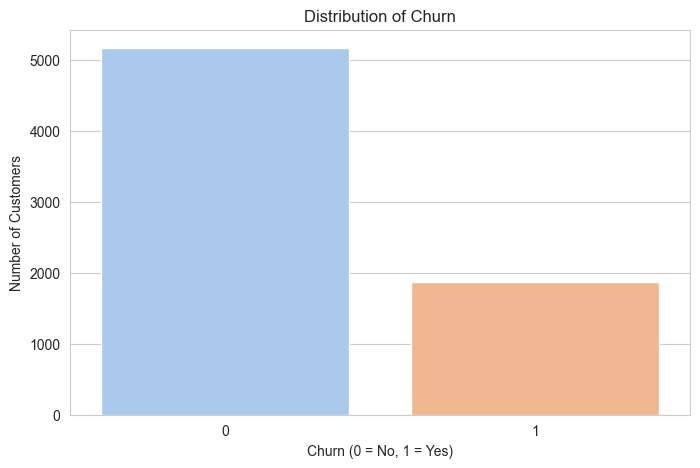

In [7]:
plt.figure()
sns.countplot(data=df, x="Churn Value", palette='pastel')
plt.title("Distribution of Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.savefig("Diagrams/churn_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

Figure 1: Distribution of churned versus non churned customers. The imbalance between the two classes is clearly visible, with non churned customers making up the majority of the dataset.

# Section 2: Numerical Feature Distributions

Tenure Months, Monthly Charges, and Total Charges are the three numerical features in the dataset whose shapes are examined in this section. Because Logistic Regression is sensitive to variations in feature scale, examining these distributions aids in determining whether scaling is required prior to modelling (Sana et al., 2022).

Total Charges is still stored as text at this point, so it is converted to a number just for this plot. The actual fix for its missing values happens later in preprocessing.

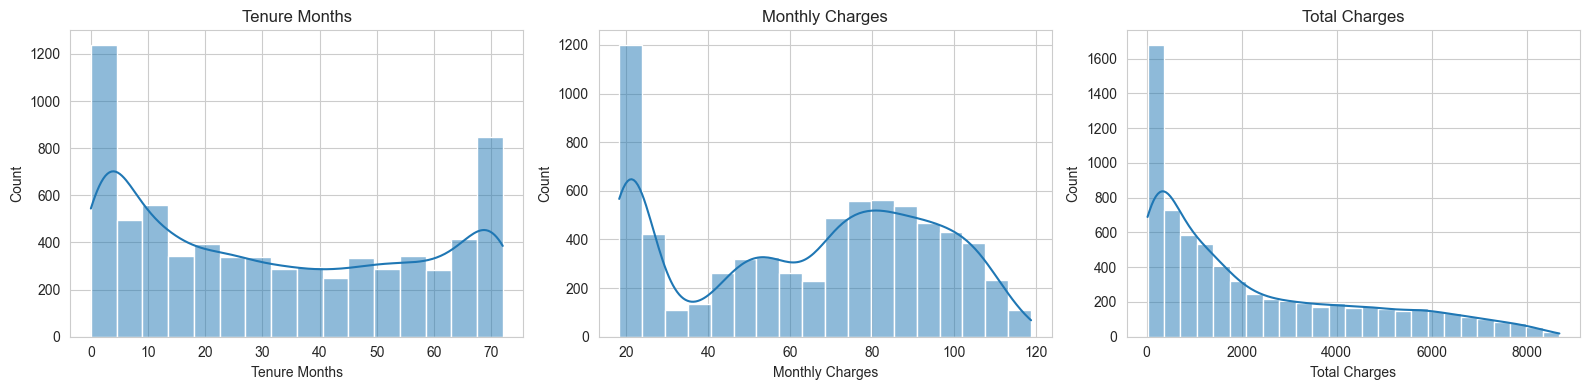

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["Tenure Months"], kde=True, ax=axes[0])
axes[0].set_title("Tenure Months")

sns.histplot(df["Monthly Charges"], kde=True, ax=axes[1])
axes[1].set_title("Monthly Charges")

sns.histplot(pd.to_numeric(df["Total Charges"], errors='coerce'), kde=True, ax=axes[2])
axes[2].set_title("Total Charges")

plt.tight_layout()
plt.savefig("Diagrams/numerical_distributions.png", dpi=150, bbox_inches='tight')
plt.show()

## Interpretation:
Both Tenure Months and Monthly Charges exhibit bimodal distributions, indicating that the client base comprises distinct segments rather than a homogeneous group. This trend likely stems from a divergence between basic account holders and clients subscribed to comprehensive, higher-tier packages.

Conversely, Total Charges exhibits significant right-skewness, a natural byproduct of cost aggregation over time. Consequently, feature scaling is crucial prior to model fitting especially for Logistic Regression to prevent features with larger magnitude ranges from disproportionately influencing the algorithm's parameter estimation (Sana et al., 2022).

Figure 2: Distribution profiles for Tenure Months, Monthly Charges, and Total Charges. The former two exhibit dual-peak structures, whereas the latter displays positive skewness.

# Section 3: Numerical Features Against Churn

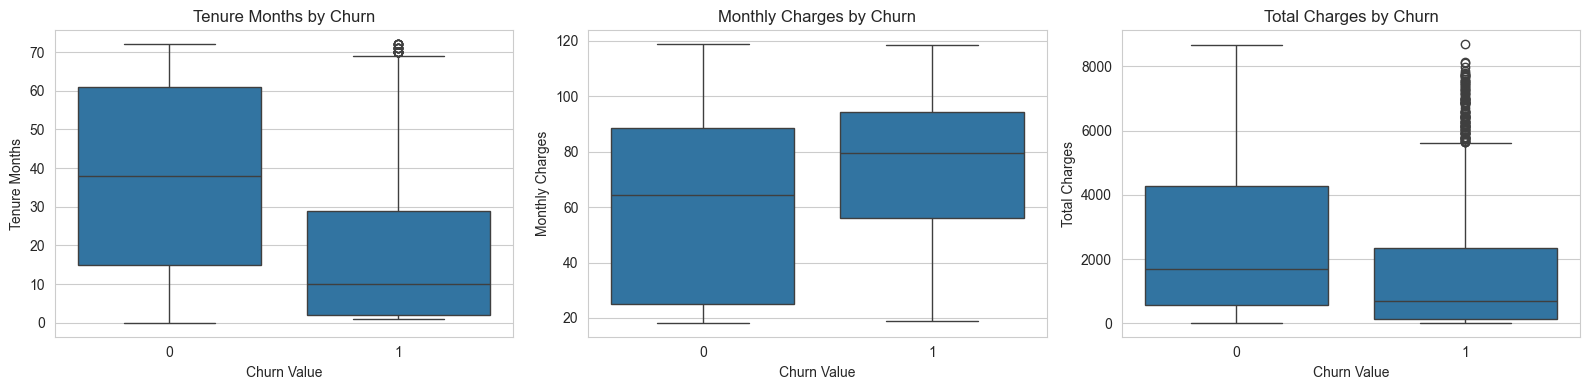

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=df, x="Churn Value", y="Tenure Months", ax=axes[0])
axes[0].set_title("Tenure Months by Churn")

sns.boxplot(data=df, x="Churn Value", y="Monthly Charges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")

plot_df = df.copy()
plot_df["Total Charges"] = pd.to_numeric(plot_df["Total Charges"], errors='coerce')
sns.boxplot(data=plot_df, x="Churn Value", y="Total Charges", ax=axes[2])
axes[2].set_title("Total Charges by Churn")

plt.tight_layout()
plt.savefig("Diagrams/numerical_vs_churn.png", dpi=150, bbox_inches='tight')
plt.show()

## Interpretation:
A pattern appears in all three charts. The median Tenure Months of churned customers are significantly lower, and the closely clustered box indicates that this is more likely to occur early in the customer relationship than to occur gradually over time. Churn is more prevalent within a certain group of higher-spending consumers rather than being dispersed randomly across all spending levels, as seen by the fact that churned customers have a higher median Monthly Charges and are also closely clustered.

This appears to be at odds with the Total Charges graphic, which actually displays a lower median for churned clients. But when the first two results are taken together, this makes sense. Churned clients do not stay long enough to accrue as high a Total Charges as customers who stay with the company longer, even at a lower monthly rate, because they pay more each month but depart earlier.

Figure 3: Tenure Months, Monthly Charges, and Total Charges compared between churned and non-churned customers. Churned customers show lower tenure, higher monthly charges, and lower total charges, suggesting churn tends to occur early among higher paying customers.

# Section 4: Categorical Features Against Churn

This section checks whether categorical features like contract type and payment method relate to churn. Contract type and tenure were repeatedly identified as strong churn predictors in the literature (Sinaga and Widianto, 2023; Peng and Peng, 2022), so this is a chance to see if that pattern shows up in this dataset too.

For readability, a temporary Churn Status column is created here, labelling customers as Stayed or Churned instead of 0 or 1. This is only used for plotting, the original Churn Value column is kept as is for modelling later.

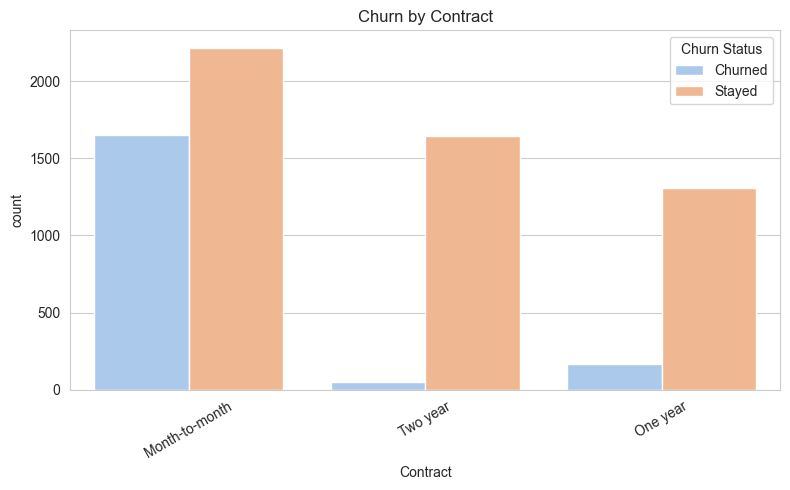

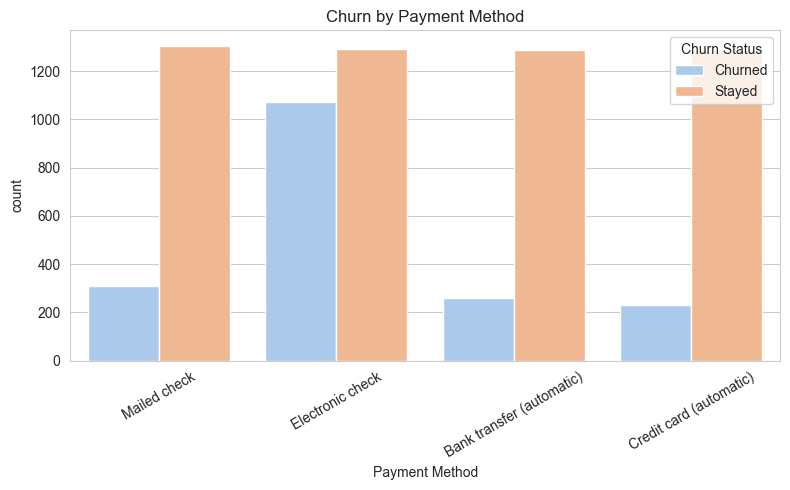

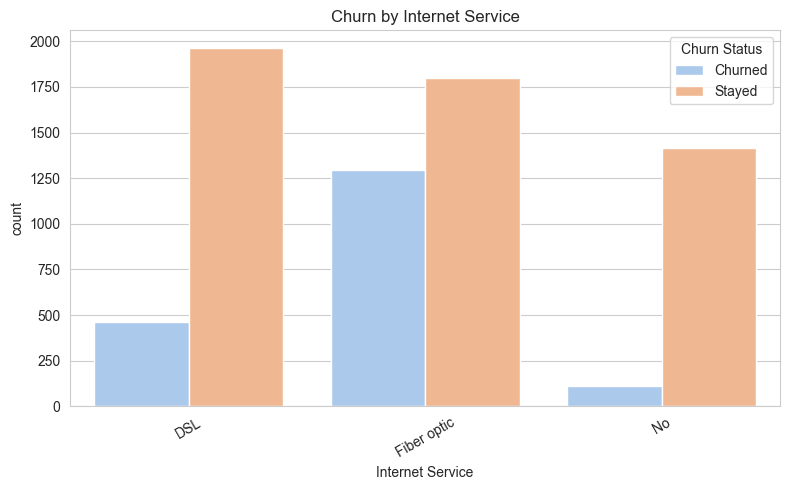

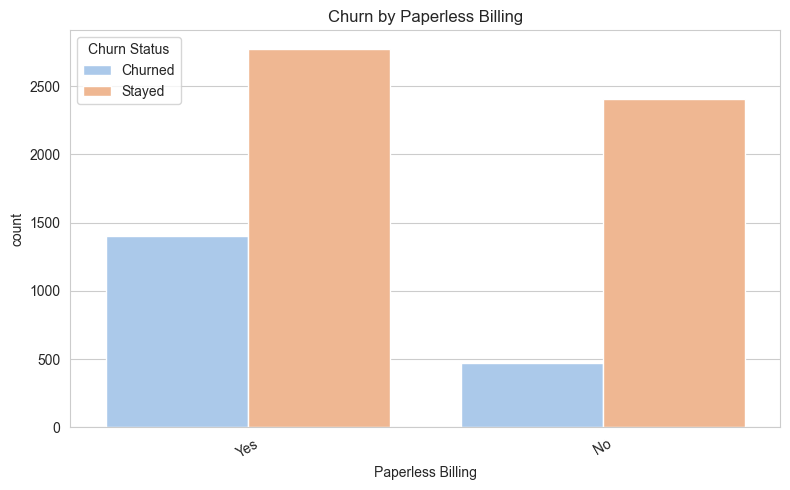

In [10]:
df["Churn Status"] = df["Churn Value"].map({0: "Stayed", 1: "Churned"})

categorical_checks = ["Contract", "Payment Method", "Internet Service", "Paperless Billing"]

for col in categorical_checks:
    plt.figure()
    sns.countplot(data=df, x=col, hue="Churn Status", palette='pastel')
    plt.title(f"Churn by {col}")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.savefig(f"Diagrams/churn_by_{col.replace(' ', '_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

## Interpretation:

Among the four category characteristics, contract type has the largest correlation with churn. Due to the fact that they are not bound by a long-term commitment and are not penalised for quitting, customers on month-to-month contracts churn considerably higher than those on one or two-year contracts. This is consistent with what was found to be one of the best churn predictors in earlier studies by Sinaga and Widianto (2023) and Peng and Peng (2022).

The payment mechanism has a similarly distinct pattern, with clients using electronic checks churning far more than those using credit cards, bank transfers, or mailed checks. Additionally, there is a disparity in internet service, with fibre optic subscribers churning the most, followed by DSL, and those without internet service churning the least. Since fibre optic is usually the more costly internet option, this relates to a previous discovery in Section 3 where churned consumers were found to cluster around higher Monthly Charges.

Paperless Billing shows the weakest relationship of the four. Customers with paperless billing enabled do churn somewhat more than those without it, but the difference is much smaller than what was seen for Contract or Payment Method.

Figure 4: Churn compared across Contract, Payment Method, Internet Service, and Paperless Billing. Contract type shows the strongest relationship with churn, followed by Payment Method and Internet Service, while Paperless Billing shows the weakest difference.

# Section 5: Correlation Between Numerical Features

This section checks how strongly Tenure Months, Monthly Charges, and Total Charges relate to each other. This is mainly a quick check before preprocessing, high correlation between features can sometimes cause issues for certain models, so it is worth confirming here.

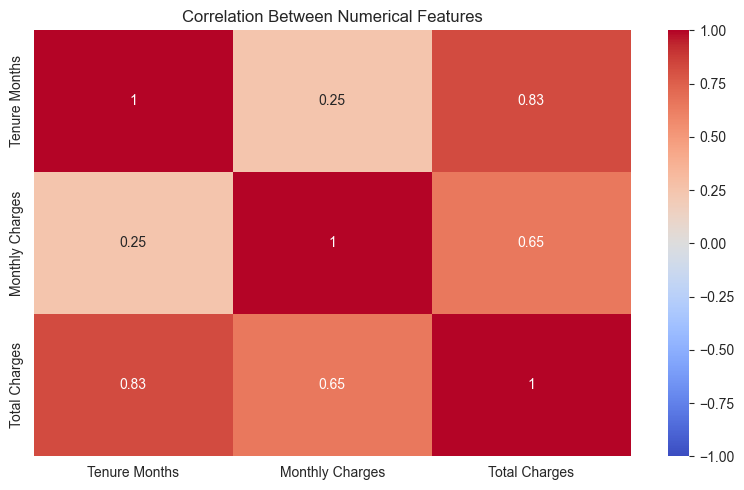

In [11]:
plot_df = df.copy()
plot_df["Total Charges"] = pd.to_numeric(plot_df["Total Charges"], errors='coerce')

numerical_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]
corr_matrix = plot_df[numerical_cols].corr()

plt.figure()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.savefig("Diagrams/correlation_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

## Interpretation:

There is a significant 0.83 association between Tenure Months and Total Charges. Given the relationship between these two aspects, it makes clear that customers with longer tenure naturally acquire greater Total Charges over time, regardless of churn status. This is because Total Charges increases with the length of time a client stays with the organization. The connection between Monthly Charges and Tenure Months (0.25) and Total Charges (0.65) is lower.

This degree of association is deemed insufficient to necessitate the elimination of a feature. Correlated characteristics have little effect on tree-based models like Random Forest and LightGBM, but they can have a greater impact on Logistic Regression. Nevertheless, all three numerical features will be kept for modelling because the association is high but not nearly perfect.

Figure 5: Correlation between Tenure Months, Monthly Charges, and Total Charges. Tenure Months and Total Charges show the strongest relationship, consistent with Total Charges accumulating over a customer's tenure.

# Section 6: Demographic Features Against Churn

This section examines whether churn varies according to senior citizen status and gender. This is included because, rather than supposing that the model acts uniformly for all demographic groups, the proposal's ethical considerations demand that model performance be examined across demographic groupings.

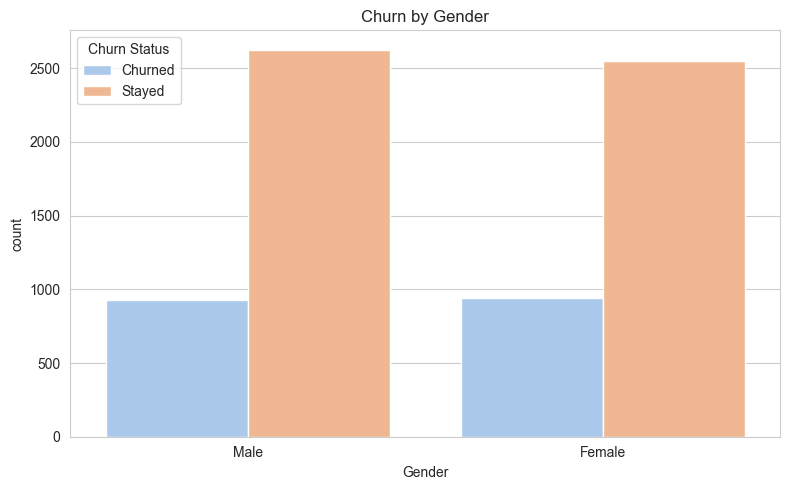

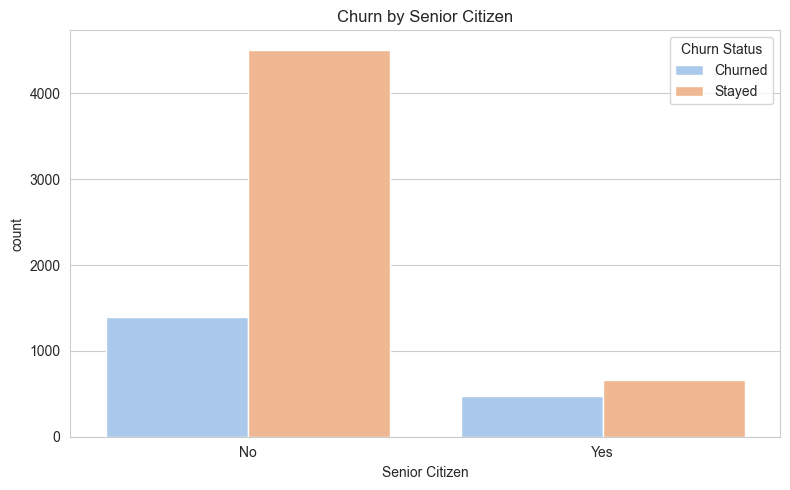

In [12]:
demographic_checks = ["Gender", "Senior Citizen"]

for col in demographic_checks:
    plt.figure()
    sns.countplot(data=df, x=col, hue="Churn Status", palette='pastel')
    plt.title(f"Churn by {col}")
    plt.tight_layout()
    plt.savefig(f"Diagrams/churn_by_{col.replace(' ', '_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

In [13]:
print(df.groupby("Senior Citizen")["Churn Value"].mean() * 100)

Senior Citizen
No     23.606168
Yes    41.681261
Name: Churn Value, dtype: float64


In [14]:
pd.crosstab(df["Senior Citizen"], df["Payment Method"], normalize='index') * 100

Payment Method,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Senior Citizen,,,,
No,22.216573,22.047111,30.011862,25.724453
Yes,20.402802,19.352014,52.014011,8.231173


## Interpretation:

The churn rate for elderly persons is significantly greater than that of non-seniors, at roughly 41.7% as opposed to 23.6%. At first, it was thought that this would have something to do with seniors not using electronic payment methods, but examining the data reveals the contrary. In actuality, seniors utilise electronic checks significantly more frequently than non-seniors roughly 52% versus 30% and use all other payment methods less frequently than non-seniors.

Since electronic checks were already noted as the payment method with the highest turnover rate in Section 4, this pattern is significant. The overlap between these two data indicates that the use of electronic checks and senior citizen status may be related, but it does not prove that one causes the other only that the two tendencies tend to coexist. When SHAP analysis is used later in the modelling process, it can assist distinguish each feature's unique contribution, which may make this link more apparent.

Figure 6: Churn by Gender and Senior Citizen status, alongside payment method usage by Senior Citizen group. Gender shows no meaningful difference in churn, while Senior Citizen status shows a notably higher churn rate, closely tied to a higher rate of Electronic check usage within that group.

# Section 7: Overview of Remaining Service Features

The remaining service-related columns that were not addressed in previous sections are briefly summarised in this section. Based on what was learned in Section 6, churn rate is computed directly for each category rather than comparing raw counts because some of the categories within these columns have extremely varied group sizes.

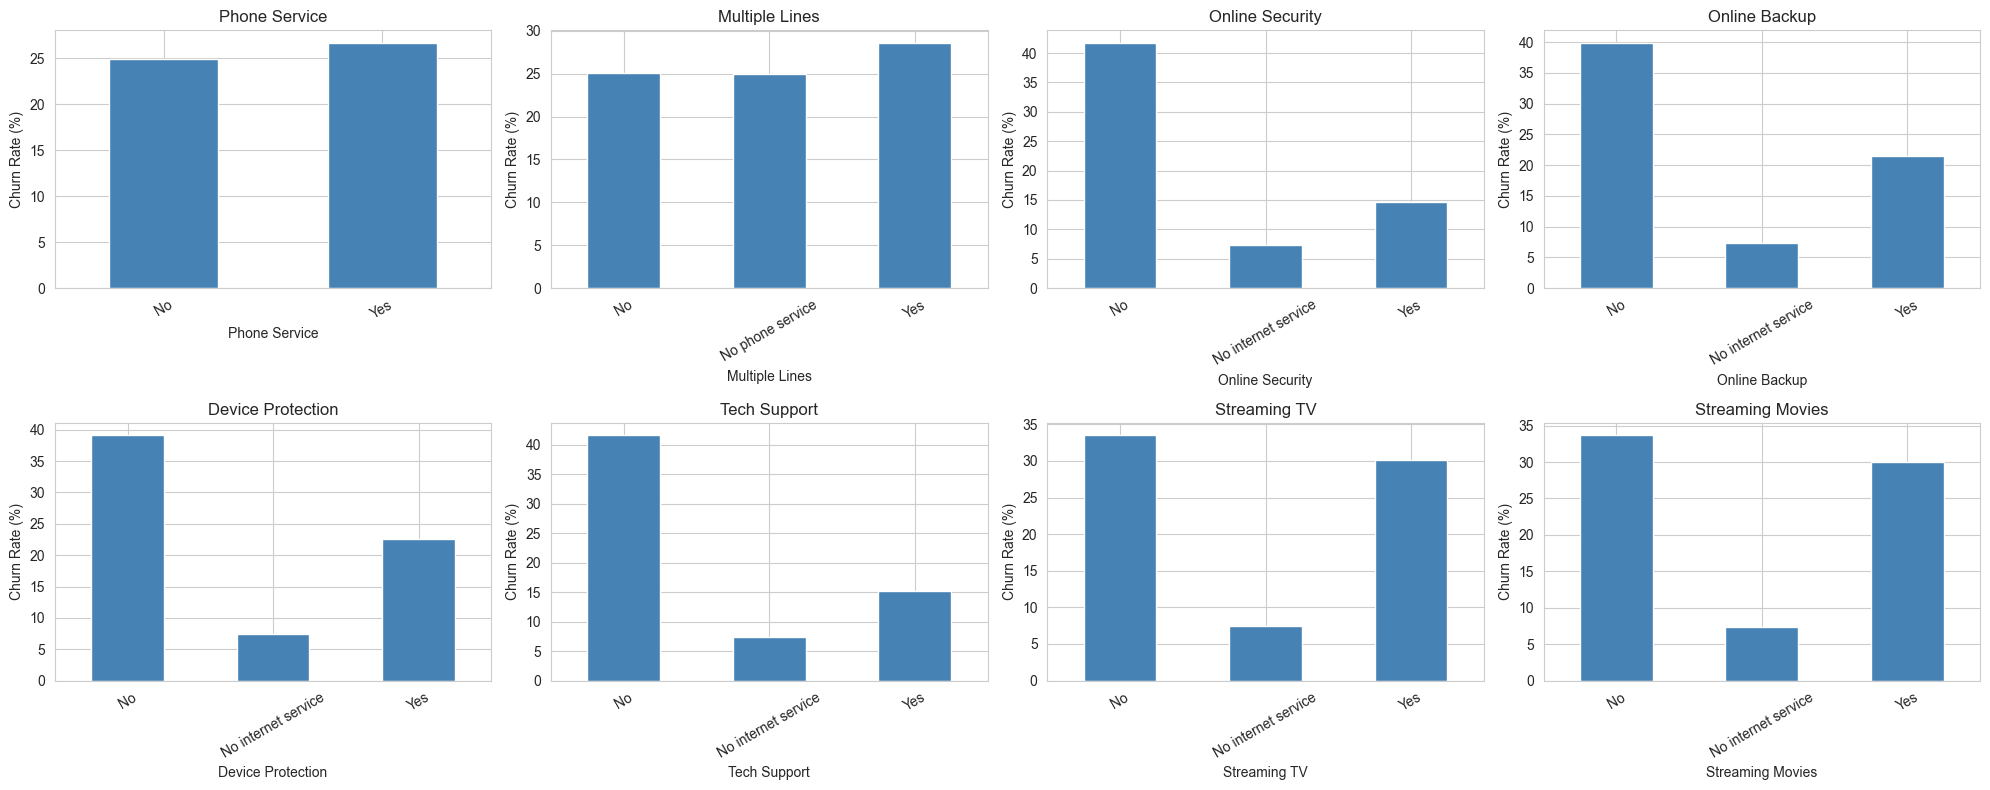

In [15]:
remaining_service_cols = ["Phone Service", "Multiple Lines", "Online Security", "Online Backup",
                           "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()

for ax, col in zip(axes, remaining_service_cols):
    churn_rate = df.groupby(col)["Churn Value"].mean() * 100
    churn_rate.plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_ylabel("Churn Rate (%)")
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig("Diagrams/remaining_service_features_churn_rate.png", dpi=150, bbox_inches='tight')
plt.show()

## Interpretation:

Customers with and without phone service and multiple lines had very identical attrition rates, ranging from 25 to 28 percent across all categories. Churn does not seem to be significantly correlated with these two characteristics.

A more coherent narrative is presented by the remaining six service features. Customers who do not have online security, online backup, device protection, and tech support churn at a rate of about 39 to 42 percent, but those who do churn at a rate of just about 15 to 23 percent. A lesser version of the same pattern can be seen in streaming TV and streaming films, where consumers who don't have either service churn at about 33 to 34 percent, while those who do have them churn at about 30 percent, with only a slight difference.

In all six of these features, the "No internet service" category has the lowest turnover rate, which is to be expected given that this group completely overlaps with the consumers who were previously found to have the lowest overall churn in Section 4.

All things considered, this indicates that consumers who purchase protective or support-related add-ons, such Online Security and Tech Support, are far less likely to leave than those who do not, even more so than those who purchase entertainment-focused add-ons, like Streaming TV. This may indicate that security and support services have a greater impact on customer retention than entertainment services, but after SHAP analysis determines which aspects truly influence the models' predictions, this pattern merits more investigation.

Figure 7: Churn rate across the remaining service related features. Online Security, Online Backup, Device Protection, and Tech Support show the largest differences in churn rate between customers who have the service and those who do not, while Phone Service and Multiple Lines show almost no difference.

# Preprocessing



The following steps clean and prepare the dataset for modelling, following the pipeline described in the Methodology section of the proposal. This involves dropping unnecessary or leakage prone columns, fixing missing values, and encoding categorical variables into a numeric form the models can use.

## Preprocessing Step 1: Drop Excluded Columns

Here, the columns mentioned in the proposal's Table 1 are eliminated. These are either features that would directly leak the result into the model (Churn Score, CLTV, Churn Reason), identifiers with little predictive value, or geographic fields with no true variance because the dataset is synthetic. Since Churn Value is already being utilised and Churn Label is merely a text form of it, it is likewise dropped here.

In [17]:
columns_to_drop = [
    "CustomerID", "Count", "Country", "State", "City", "Zip Code",
    "Lat Long", "Latitude", "Longitude",
    "Churn Score", "CLTV", "Churn Reason", "Churn Label",
    "Churn Status"
]

df_clean = df.drop(columns=columns_to_drop)
print("Shape before:", df.shape)
print("Shape after dropping:", df_clean.shape)
df_clean.head()

Shape before: (7043, 34)
Shape after dropping: (7043, 20)


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,1


## Preprocessing Step 2: Fix Total Charges Missing Values

Eleven blank numbers were found previously during the data quality check, and Total Charges is presently stored as text. Following the methodology of Sana et al. (2022), this step turns the column to a correct number and uses the median to fill in the missing values because median imputation is less impacted by outliers than using the mean.

In [18]:
df_clean["Total Charges"] = pd.to_numeric(df_clean["Total Charges"], errors='coerce')

missing_before = df_clean["Total Charges"].isnull().sum()
median_value = df_clean["Total Charges"].median()
df_clean["Total Charges"] = df_clean["Total Charges"].fillna(median_value)

print("Missing values before imputation:", missing_before)
print("Median value used:", median_value)
print("Missing values after imputation:", df_clean["Total Charges"].isnull().sum())

Missing values before imputation: 11
Median value used: 1397.475
Missing values after imputation: 0


## Preprocessing Step 3: Encode Categorical Variables

Binary columns are mapped directly to 0 and 1. Multi-category columns are one hot encoded, so no artificial order gets implied between categories that do not have one, such as different payment methods (Sana et al., 2022).

In [19]:
binary_cols = ["Senior Citizen", "Partner", "Dependents", "Phone Service", "Paperless Billing"]
for col in binary_cols:
    df_clean[col] = df_clean[col].map({"Yes": 1, "No": 0})

df_clean["Gender"] = df_clean["Gender"].map({"Male": 1, "Female": 0})

multi_cols = ["Multiple Lines", "Internet Service", "Online Security", "Online Backup",
              "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies",
              "Contract", "Payment Method"]

df_clean = pd.get_dummies(df_clean, columns=multi_cols, drop_first=True)

print("Shape after encoding:", df_clean.shape)
df_clean.head()

Shape after encoding: (7043, 31)


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Paperless Billing,Monthly Charges,Total Charges,Churn Value,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_Fiber optic,Internet Service_No,Online Security_No internet service,Online Security_Yes,Online Backup_No internet service,Online Backup_Yes,Device Protection_No internet service,Device Protection_Yes,Tech Support_No internet service,Tech Support_Yes,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,1,0,0,0,2,1,1,53.85,108.15,1,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
1,0,0,0,1,2,1,1,70.70,151.65,1,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
2,0,0,0,1,8,1,1,99.65,820.50,1,False,True,True,False,False,False,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False
3,0,0,1,1,28,1,1,104.80,3046.05,1,False,True,True,False,False,False,False,False,False,True,False,True,False,True,False,True,False,False,False,True,False
4,1,0,0,1,49,1,1,103.70,5036.30,1,False,True,True,False,False,False,False,True,False,True,False,False,False,True,False,True,False,False,False,False,False


In [20]:
bool_cols = df_clean.select_dtypes(include='bool').columns
df_clean[bool_cols] = df_clean[bool_cols].astype(int)

df_clean.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Paperless Billing,Monthly Charges,Total Charges,Churn Value,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_Fiber optic,Internet Service_No,Online Security_No internet service,Online Security_Yes,Online Backup_No internet service,Online Backup_Yes,Device Protection_No internet service,Device Protection_Yes,Tech Support_No internet service,Tech Support_Yes,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,1,0,0,0,2,1,1,53.85,108.15,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
1,0,0,0,1,2,1,1,70.70,151.65,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,0,0,0,1,8,1,1,99.65,820.50,1,0,1,1,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,0
3,0,0,1,1,28,1,1,104.80,3046.05,1,0,1,1,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,0,1,0
4,1,0,0,1,49,1,1,103.70,5036.30,1,0,1,1,0,0,0,0,1,0,1,0,0,0,1,0,1,0,0,0,0,0


## Preprocessing Step 4: Save the Cleaned Dataset

The fully cleaned and encoded dataset is saved here as a standalone CSV file. This becomes the single source of truth for the modelling notebook, which will handle the train and test split, scaling, and SMOTE.

In [21]:
df_clean.to_csv("churn_cleaned.csv", index=False)
print("Saved churn_cleaned.csv with shape:", df_clean.shape)

Saved churn_cleaned.csv with shape: (7043, 31)
